In [2]:
!pip install -q pyomo

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.5/12.5 MB 47.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.6/49.6 kB 5.1 MB/s eta 0:00:00


In [3]:
from pyomo.environ import *

# create a model
model = ConcreteModel()

# declare decision variables
model.x = Var(domain=NonNegativeReals)
model.y = Var(domain=NonNegativeReals)

# declare objective
model.profit = Objective(expr = 40*model.x + 30*model.y, sense=maximize)

# declare constraints
model.demand = Constraint(expr = model.x <= 40)
model.laborA = Constraint(expr = model.x + model.y <= 80)
model.laborB = Constraint(expr = 2*model.x + model.y <= 100)

model.pprint()

2 Var Declarations
    x : Size=1, Index=None
        Key  : Lower : Value : Upper : Fixed : Stale : Domain
        None :     0 :  None :  None : False :  True : NonNegativeReals
    y : Size=1, Index=None
        Key  : Lower : Value : Upper : Fixed : Stale : Domain
        None :     0 :  None :  None : False :  True : NonNegativeReals

1 Objective Declarations
    profit : Size=1, Index=None, Active=True
        Key  : Active : Sense    : Expression
        None :   True : maximize : 40*x + 30*y

3 Constraint Declarations
    demand : Size=1, Index=None, Active=True
        Key  : Lower : Body : Upper : Active
        None :  -Inf :    x :  40.0 :   True
    laborA : Size=1, Index=None, Active=True
        Key  : Lower : Body  : Upper : Active
        None :  -Inf : x + y :  80.0 :   True
    laborB : Size=1, Index=None, Active=True
        Key  : Lower : Body    : Upper : Active
        None :  -Inf : 2*x + y : 100.0 :   True

6 Declarations: x y profit demand laborA laborB


In [4]:
!apt-get install -y -qq glpk-utils

Selecting previously unselected package libsuitesparseconfig5:amd64.
(Reading database ... 121654 files and directories currently installed.)
Preparing to unpack .../libsuitesparseconfig5_1%3a5.10.1+dfsg-4build1_amd64.deb ...
Unpacking libsuitesparseconfig5:amd64 (1:5.10.1+dfsg-4build1) ...
Selecting previously unselected package libamd2:amd64.
Preparing to unpack .../libamd2_1%3a5.10.1+dfsg-4build1_amd64.deb ...
Unpacking libamd2:amd64 (1:5.10.1+dfsg-4build1) ...
Selecting previously unselected package libcolamd2:amd64.
Preparing to unpack .../libcolamd2_1%3a5.10.1+dfsg-4build1_amd64.deb ...
Unpacking libcolamd2:amd64 (1:5.10.1+dfsg-4build1) ...
Selecting previously unselected package libglpk40:amd64.
Preparing to unpack .../libglpk40_5.0-1_amd64.deb ...
Unpacking libglpk40:amd64 (5.0-1) ...
Selecting previously unselected package glpk-utils.
Preparing to unpack .../glpk-utils_5.0-1_amd64.deb ...
Unpacking glpk-utils (5.0-1) ...
Setting up libsuitesparseconfig5:amd64 (1:5.10.1+dfsg-4b

In [5]:
SolverFactory('glpk', executable='/usr/bin/glpsol').solve(model).write()

# display solution
print('\nProfit = ', model.profit())

print('\nDecision Variables')
print('x = ', model.x())
print('y = ', model.y())

print('\nConstraints')
print('Demand  = ', model.demand())
print('Labor A = ', model.laborA())
print('Labor B = ', model.laborB())

# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Name: unknown
  Lower bound: 2600.0
  Upper bound: 2600.0
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 2
  Number of nonzeros: 5
  Sense: maximize
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: ok
  Termination condition: optimal
  Statistics: 
    Branch and bound: 
      Number of bounded subproblems: 0
      Number of created subproblems: 0
  Error rc: 0
  Time: 0.004243612289428711
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------

In [6]:
!apt-get install -y -qq coinor-cbc

Selecting previously unselected package coinor-libcoinutils3v5:amd64.
(Reading database ... 121857 files and directories currently installed.)
Preparing to unpack .../0-coinor-libcoinutils3v5_2.11.4+repack1-2_amd64.deb ...
Unpacking coinor-libcoinutils3v5:amd64 (2.11.4+repack1-2) ...
Selecting previously unselected package coinor-libosi1v5:amd64.
Preparing to unpack .../1-coinor-libosi1v5_0.108.6+repack1-2_amd64.deb ...
Unpacking coinor-libosi1v5:amd64 (0.108.6+repack1-2) ...
Selecting previously unselected package coinor-libclp1.
Preparing to unpack .../2-coinor-libclp1_1.17.5+repack1-1_amd64.deb ...
Unpacking coinor-libclp1 (1.17.5+repack1-1) ...
Selecting previously unselected package coinor-libcgl1:amd64.
Preparing to unpack .../3-coinor-libcgl1_0.60.3+repack1-3_amd64.deb ...
Unpacking coinor-libcgl1:amd64 (0.60.3+repack1-3) ...
Selecting previously unselected package coinor-libcbc3:amd64.
Preparing to unpack .../4-coinor-libcbc3_2.10.7+ds1-1_amd64.deb ...
Unpacking coinor-libcbc3:

In [7]:
SolverFactory('cbc', executable='/usr/bin/cbc').solve(model).write()

# display solution
print('\nProfit = ', model.profit())

print('\nDecision Variables')
print('x = ', model.x())
print('y = ', model.y())

print('\nConstraints')
print('Demand  = ', model.demand())
print('Labor A = ', model.laborA())
print('Labor B = ', model.laborB())

# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Name: unknown
  Lower bound: 2600.0
  Upper bound: 2600.0
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 2
  Number of nonzeros: 2
  Sense: maximize
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: ok
  User time: -1.0
  System time: 0.0
  Wallclock time: 0.0
  Termination condition: optimal
  Termination message: Model was solved to optimality (subject to tolerances), and an optimal solution is available.
  Statistics: 
    Branch and bound: 
      Number of bounded subproblems: None
      Number of created s

In [8]:
!wget -N -q "https://github.com/thomasfork/ipopt_linux/raw/main/ipopt-linux64.zip"
!unzip -o -q ipopt-linux64

In [9]:
SolverFactory('ipopt', executable='/content/ipopt').solve(model).write()

# display solution
print('\nProfit = ', model.profit())

print('\nDecision Variables')
print('x = ', model.x())
print('y = ', model.y())

print('\nConstraints')
print('Demand  = ', model.demand())
print('Labor A = ', model.laborA())
print('Labor B = ', model.laborB())

# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 2
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: ok
  Message: Ipopt 3.12.13\x3a Optimal Solution Found
  Termination condition: optimal
  Id: 0
  Error rc: 0
  Time: 0.008599519729614258
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of solutions: 0
  number of solutions displayed: 0

Profi

In [10]:
# Grilles locales : Hashi2.csv, Hashi3.csv, Hashi4.csv


Mounted at /content/drive


In [11]:
hashi2='Hashi2.csv'
hashi3='Hashi3.csv'
hashi4='Hashi4.csv'

In [12]:
from shapely.geometry import LineString
import matplotlib.pyplot as plt
import numpy as np
import random
import pandas as pd
from pyomo.environ import *

In [13]:
L1 = [(0, 0), (13, 1)]
L2 = [(0.2, 3), (4.2, 3)]

line = LineString([L1[0], L1[1]])
other = LineString([L2[0], L2[1]])
print(line.intersects(other))
# True
df= pd.read_csv(hashi4)

df= df.fillna(0)
df

xmax = len(df.columns)
ymax =len(df)
print(xmax ,ymax)

data, points, c ={}, {}, 0
for x in range(xmax):
    for y in range(ymax):
        if int(df.iloc[y,x]) >0:
            c+=1
            data[c,'x'] =x
            data[c,'y'] =y
            data[c,'v'] =int(df.iloc[y,x])
            print(x,y,int(df.iloc[y,x]))

data

False
12 12
0 0 2
0 3 4
0 6 4
0 9 3
0 11 2
1 7 1
2 1 2
2 3 8
2 5 3
2 11 2
3 0 4
3 2 2
3 7 3
3 9 3
4 1 3
4 3 3
4 6 2
4 8 2
4 11 3
5 2 2
5 5 3
6 0 2
6 6 2
6 8 4
6 10 3
7 3 3
7 5 4
7 7 2
7 9 1
7 11 2
8 1 2
8 4 2
8 6 3
8 8 3
8 10 2
9 3 2
9 5 2
9 9 2
9 11 3
10 0 3
10 2 3
10 4 3
10 6 1
11 1 2
11 3 3
11 5 4
11 8 4
11 11 2


{(1, 'x'): 0,
 (1, 'y'): 0,
 (1, 'v'): 2,
 (2, 'x'): 0,
 (2, 'y'): 3,
 (2, 'v'): 4,
 (3, 'x'): 0,
 (3, 'y'): 6,
 (3, 'v'): 4,
 (4, 'x'): 0,
 (4, 'y'): 9,
 (4, 'v'): 3,
 (5, 'x'): 0,
 (5, 'y'): 11,
 (5, 'v'): 2,
 (6, 'x'): 1,
 (6, 'y'): 7,
 (6, 'v'): 1,
 (7, 'x'): 2,
 (7, 'y'): 1,
 (7, 'v'): 2,
 (8, 'x'): 2,
 (8, 'y'): 3,
 (8, 'v'): 8,
 (9, 'x'): 2,
 (9, 'y'): 5,
 (9, 'v'): 3,
 (10, 'x'): 2,
 (10, 'y'): 11,
 (10, 'v'): 2,
 (11, 'x'): 3,
 (11, 'y'): 0,
 (11, 'v'): 4,
 (12, 'x'): 3,
 (12, 'y'): 2,
 (12, 'v'): 2,
 (13, 'x'): 3,
 (13, 'y'): 7,
 (13, 'v'): 3,
 (14, 'x'): 3,
 (14, 'y'): 9,
 (14, 'v'): 3,
 (15, 'x'): 4,
 (15, 'y'): 1,
 (15, 'v'): 3,
 (16, 'x'): 4,
 (16, 'y'): 3,
 (16, 'v'): 3,
 (17, 'x'): 4,
 (17, 'y'): 6,
 (17, 'v'): 2,
 (18, 'x'): 4,
 (18, 'y'): 8,
 (18, 'v'): 2,
 (19, 'x'): 4,
 (19, 'y'): 11,
 (19, 'v'): 3,
 (20, 'x'): 5,
 (20, 'y'): 2,
 (20, 'v'): 2,
 (21, 'x'): 5,
 (21, 'y'): 5,
 (21, 'v'): 3,
 (22, 'x'): 6,
 (22, 'y'): 0,
 (22, 'v'): 2,
 (23, 'x'): 6,
 (23, 'y'): 6,
 (23

In [14]:
Nc = c

points = [i for i in range(1,1+Nc)]

lines , ALL_lines= {}, {}
for c1 in points:
    for c2 in points:
        condition1 = data[c1,'x'] == data[c2,'x']
        condition2 = data[c1,'y'] == data[c2,'y']
        if c1!=c2 and (condition1 or condition2) and c1>c2:
            lines[c1,c2] = 1
        if c1!=c2 and (condition1 or condition2):
            ALL_lines[c1,c2] = 1

lines
df, data

(     a1   a2   a3   a4   a5   a6   a7   a8   a9  a10  a11  a12
 0   2.0  0.0  0.0  4.0  0.0  0.0  2.0  0.0  0.0  0.0  3.0  0.0
 1   0.0  0.0  2.0  0.0  3.0  0.0  0.0  0.0  2.0  0.0  0.0  2.0
 2   0.0  0.0  0.0  2.0  0.0  2.0  0.0  0.0  0.0  0.0  3.0  0.0
 3   4.0  0.0  8.0  0.0  3.0  0.0  0.0  3.0  0.0  2.0  0.0  3.0
 4   0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  2.0  0.0  3.0  0.0
 5   0.0  0.0  3.0  0.0  0.0  3.0  0.0  4.0  0.0  2.0  0.0  4.0
 6   4.0  0.0  0.0  0.0  2.0  0.0  2.0  0.0  3.0  0.0  1.0  0.0
 7   0.0  1.0  0.0  3.0  0.0  0.0  0.0  2.0  0.0  0.0  0.0  0.0
 8   0.0  0.0  0.0  0.0  2.0  0.0  4.0  0.0  3.0  0.0  0.0  4.0
 9   3.0  0.0  0.0  3.0  0.0  0.0  0.0  1.0  0.0  2.0  0.0  0.0
 10  0.0  0.0  0.0  0.0  0.0  0.0  3.0  0.0  2.0  0.0  0.0  0.0
 11  2.0  0.0  2.0  0.0  3.0  0.0  0.0  2.0  0.0  3.0  0.0  2.0,
 {(1, 'x'): 0,
  (1, 'y'): 0,
  (1, 'v'): 2,
  (2, 'x'): 0,
  (2, 'y'): 3,
  (2, 'v'): 4,
  (3, 'x'): 0,
  (3, 'y'): 6,
  (3, 'v'): 4,
  (4, 'x'): 0,
  (4, 'y'): 9,
  

In [15]:
def draw(L, LW=1):
    if LW > 1:
        LW =8
        plt.plot([L[0][0],L[1][0]], [L[0][1],L[1][1]], lw=LW)
    else:
        plt.plot([L[0][0],L[1][0]], [L[0][1],L[1][1]], lw=2, c= 'k')

In [16]:
model = AbstractModel()
model.i = RangeSet(Nc)
model.j = Set(initialize=model.i)

model.X = Var(model.i,model.j,bounds=(0,2),initialize=0, within=Integers)
model.U = Var(model.i,model.j,bounds=(0,1),initialize=0, within=Binary)
model.flow = Var(model.i,model.j,bounds=(0,1),initialize=0, within=Reals)
model.s = Var(bounds=(0,1),initialize=0, within=Reals)


def rule_C1(model,c):
    return   data[c,'v'] == sum(model.X[c,j] for j in model.j if (c,j) in lines) +\
                            sum(model.X[j,c] for j in model.j if (j,c) in lines)
model.C1 = Constraint(model.i,rule=rule_C1)


def rule_C2(model,m,n,i,j):
    L1 = [(data[i,'x'],data[i,'y']), (data[j,'x'],data[j,'y'])]
    L2 = [(data[m,'x'],data[m,'y']), (data[n,'x'],data[n,'y'])]
    line = LineString([L1[0], L1[1]])
    other = LineString([L2[0], L2[1]])
    a = line.intersection(other)
    a = line.intersection(other)
    cancel_con = len(set([i,j,m,n])) <4
    con0 = (m,n) in lines and (i,j) in lines and (m,n)!=(i,j) and (m*n>i*j)
    con1 = con0 and (not cancel_con) and line.intersects(other)
    con2 = con0 and (cancel_con and a.length> 1) and line.intersects(other) and (m,n)!=(i,j) and (m*n>i*j)
    if con1 or con2:
        return   model.U[i,j]+model.U[m,n] <= 1
    else:
        return Constraint.Skip
model.C2 = Constraint(model.i,model.i,model.i,model.i, rule=rule_C2)


def rule_C3(model,i,j):
    if (i,j) in lines:
        return   model.X[i,j]<= 2*model.U[i,j]
    else:
        return Constraint.Skip
model.C3 = Constraint(model.i,model.j, rule=rule_C3)

def rule_C3B(model,i,j):
    if (i,j) in lines:
        return   model.X[i,j]>= model.U[i,j]
    else:
        return Constraint.Skip
model.C3B = Constraint(model.i,model.j, rule=rule_C3B)


def rule_C4A(model,i):
    if i ==1 :
        return model.s - 0.001 == sum( model.flow[i,j]-model.flow[j,i] for j in model.j if (i,j) in ALL_lines )
    else:
        return         - 0.001 == sum( model.flow[i,j]-model.flow[j,i] for j in model.j if (i,j) in ALL_lines )
model.C4A = Constraint(model.i, rule=rule_C4A)
def rule_C4B(model,i,j):
    if (i,j) in lines:
        return   model.flow[i,j]<= model.U[i,j]
    elif (j,i) in lines:
        return   model.flow[i,j]<= model.U[j,i]
    else:
        return Constraint.Skip
model.C4B = Constraint(model.i,model.j, rule=rule_C4B)

def rule_OF(model):
    return  sum(model.U[i,j] for (i,j) in lines)
model.obj1 = Objective(rule=rule_OF, sense=minimize)
instance = model.create_instance()

In [17]:
opt = SolverFactory('cbc')
opt.options = {'sec': 600, 'threads': 4, 'ratio': 0.1}
results = opt.solve(instance)

from pyomo.opt import SolverStatus, TerminationCondition
if (results.solver.status == SolverStatus.ok) and (results.solver.termination_condition == TerminationCondition.optimal):
     print ("this is feasible and optimal and nothing more")
elif results.solver.termination_condition == TerminationCondition.infeasible:
     print ("do something about it? or exit?")
else:
     print ('ERROR ' + str(results.solver))
print('OF= ', value(instance.obj1) )

this is feasible and optimal and nothing more
OF=  47.0


2 1 1.0
3 2 1.0
4 3 1.0
5 4 1.0
8 2 2.0
8 7 2.0
9 8 2.0
10 5 1.0
11 1 1.0
12 11 2.0
13 6 1.0
14 4 1.0
14 13 2.0
16 8 2.0
16 15 1.0
17 3 2.0
19 10 1.0
19 18 1.0
21 9 1.0
21 20 2.0
22 11 1.0
24 18 1.0
24 23 2.0
25 24 1.0
27 26 1.0
28 27 2.0
30 19 1.0
31 15 2.0
34 33 2.0
35 25 2.0
36 26 2.0
37 27 1.0
38 29 1.0
39 30 1.0
39 38 1.0
40 22 1.0
41 40 2.0
42 32 2.0
42 41 1.0
43 33 1.0
45 44 2.0
46 37 1.0
46 45 1.0
47 34 1.0
47 46 2.0
48 39 1.0
48 47 1.0


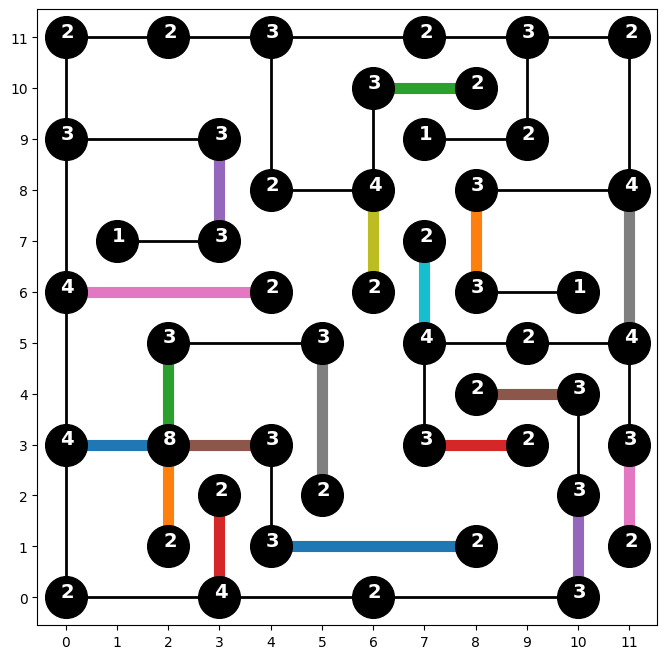

In [18]:
plt.figure(figsize=(8,8))

for i in instance.i:
    plt.scatter(data[i,'x'],data[i,'y'],s=900, c='k', zorder=3)
    plt.text(data[i,'x']-0.1,data[i,'y'],s=str(data[i,'v']), c='w', fontweight='bold', fontsize=14)

plt.savefig(f'Sashi Base .png', format='png', dpi=400)

plt.grid()
maxx, maxy= max([data[c,'x'] for c in instance.i])+1 ,  max([data[c,'y'] for c in instance.i])+1
counter = 1
for (i,j) in lines:
    if value(instance.X[i,j])>0 and counter <500:
        print(i,j, value(instance.X[i,j]))
        L = [(data[i,'x'],data[i,'y']), (data[j,'x'],data[j,'y'])]
        draw(L, value(instance.X[i,j]))
        plt.xticks(range(maxx))
        plt.yticks(range(maxy))
        counter+=1

plt.xticks(range(maxx))
plt.yticks(range(maxy))
plt.grid()

plt.savefig(f'Sashi  .png', format='png', dpi=400)

plt.show()

In [19]:
import time

start_time = time.time()
results = opt.solve(instance)
end_time = time.time()

execution_time = end_time - start_time
print(f"Execution Time: {execution_time} seconds")


Execution Time: 0.7453217506408691 seconds


In [20]:
from pyomo.environ import value

opt = SolverFactory('cbc')
opt.options = {'sec': 600, 'threads': 4, 'ratio': 0.1}
results = opt.solve(instance)

from pyomo.opt import SolverStatus, TerminationCondition

if (results.solver.status == SolverStatus.ok) and (results.solver.termination_condition == TerminationCondition.optimal):
    print("Feasible and optimal solution found.")
    print('OF=', value(instance.obj1))
elif results.solver.termination_condition == TerminationCondition.infeasible:
    print("The problem is infeasible.")
    # You can choose to take some action or exit here
else:
    print('Solver terminated with an error:', results.solver.termination_condition)
    # You may want to inspect the error and take appropriate action

# Additional information provided by the solver
print("Solver status:", results.solver.status)
print("Termination condition:", results.solver.termination_condition)


Feasible and optimal solution found.
OF= 47.0
Solver status: ok
Termination condition: optimal


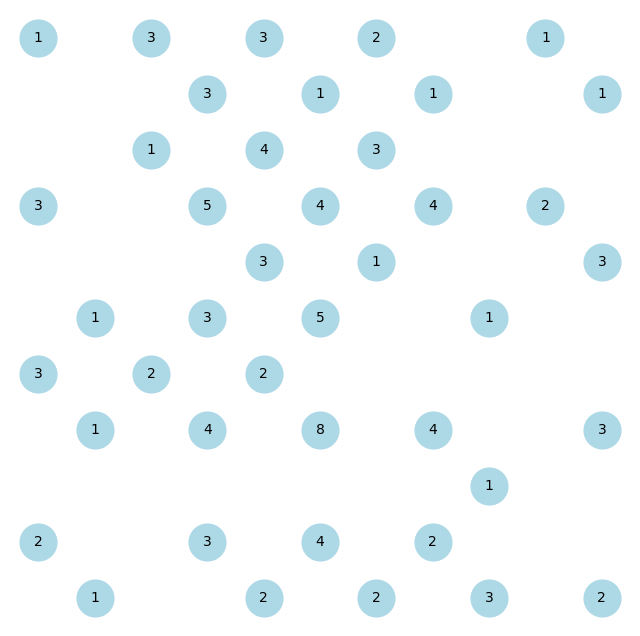

In [21]:
import matplotlib.pyplot as plt
import networkx as nx

# Définir la structure du puzzle Hashi
puzzle_data = {
    "grid": [
        [1, 0, 3, 0, 3, 0, 2, 0, 0, 1, 0],
        [0, 0, 0, 3, 0, 1, 0, 1, 0, 0, 1],
        [0, 0, 1, 0, 4, 0, 3, 0, 0, 0, 0],
        [3, 0, 0, 5, 0, 4, 0, 4, 0, 2, 0],
        [0, 0, 0, 0, 3, 0, 1, 0, 0, 0, 3],
        [0, 1, 0, 3, 0, 5, 0, 0, 1, 0, 0],
        [3, 0, 2, 0, 2, 0, 0, 0, 0, 0, 0],
        [0, 1, 0, 4, 0, 8, 0, 4, 0, 0, 3],
        [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0],
        [2, 0, 0, 3, 0, 4, 0, 2, 0, 0, 0],
        [0, 1, 0, 0, 2, 0, 2, 0, 3, 0, 2]
    ]
}

# Construire la structure de graphe
def build_graph(data):
    graph = nx.Graph()
    for i in range(len(data["grid"])):
        for j in range(len(data["grid"][i])):
            if data["grid"][i][j] > 0:
                graph.add_node((i, j), weight=data["grid"][i][j])

    for i in range(len(data["grid"])):
        for j in range(len(data["grid"][i])):
            if data["grid"][i][j] > 0:
                neighbors = [(i - 1, j), (i + 1, j), (i, j - 1), (i, j + 1)]
                for neighbor in neighbors:
                    if 0 <= neighbor[0] < len(data["grid"]) and 0 <= neighbor[1] < len(data["grid"][0]) and data["grid"][neighbor[0]][neighbor[1]] > 0:
                        graph.add_edge((i, j), neighbor)

    return graph

# Appliquer l'algorithme DFS
def dfs(graph, start_node, visited):
    visited.add(start_node)
    for neighbor in graph.neighbors(start_node):
        if neighbor not in visited:
            dfs(graph, neighbor, visited)

# Tracer les îles et les ponts
def draw_puzzle(graph, data):
    pos = {node: (node[1], -node[0]) for node in graph.nodes}
    node_labels = {node: data["grid"][node[0]][node[1]] for node in graph.nodes}

    plt.figure(figsize=(8, 8))
    nx.draw_networkx_nodes(graph, pos, node_size=700, node_color="lightblue")
    nx.draw_networkx_labels(graph, pos, labels=node_labels, font_size=10, font_color="black")
    nx.draw_networkx_edges(graph, pos, width=2, edge_color="gray")

    plt.axis("off")
    plt.show()

# Construire le graphe
hashi_graph = build_graph(puzzle_data)

# Appliquer l'algorithme DFS
start_node = list(hashi_graph.nodes)[0]
visited_nodes = set()
dfs(hashi_graph, start_node, visited_nodes)

# Tracer les îles et les ponts
draw_puzzle(hashi_graph, puzzle_data)
